# 8. Dal segnale al frame
## Ricezione, demodulazione, sincronizzazione, framing: dal segnale fisico all'unità di dato
---

## 8.0 Premessa e collocazione

Il capitolo 7 si è chiuso con una sequenza di **bit** (o di **simboli**) affetta da una certa probabilità di errore, determinata dalla modulazione, dal canale e dal rapporto $E_b/N_0$. Questo capitolo affronta il passo successivo: come quella sequenza, che è ancora un **flusso continuo e senza struttura**, viene trasformata in **unità discrete** (i frame) dotate di inizio, fine, integrità e identità.

Il percorso è composto da quattro stadi, ciascuno con la sua dose di incertezza:

1. **Ricezione** (§8.1): dal segnale RF ai campioni in banda base. È il livello fisico, già trattato nel capitolo 6 per la parte di conversione, qui ripreso per la parte di downconversion e rappresentazione complessa.
2. **Demodulazione** (§8.2): dai campioni ai simboli (hard o soft). È il livello in cui la decisione statistica (ML) diventa operativa.
3. **Sincronizzazione** (§8.3): dai simboli a un flusso allineato. È il livello in cui il ricevitore stima portante, timing e allineamento di frame. È qui che nascono le **probabilità di falsa sincronizzazione** e di **perdita di lock**.
4. **Framing** (§8.4): dal flusso allineato ai frame. È il livello in cui si segmenta, si verifica l'integrità, si estrae l'identità e il timestamp.

Il capitolo si chiude con l'analisi statistica del framing (§8.5), con esempi Python (§8.6), e con la sintesi (§8.7). Il riferimento è sempre la catena del dato: ogni stadio introduce un contributo di incertezza, e la statistica è il linguaggio con cui lo si descrive.

---

## 8.1 La catena di ricezione: dal segnale RF ai campioni

### Definizione 8.1.1 — Front-end RF e downconversion

Il segnale che arriva dall'antenna è un segnale **passa-banda** centrato su una frequenza portante $f_c$, di banda $B$:

$$
r_{RF}(t) = \text{Re}\left\{ r_{BB}(t) \, e^{j2\pi f_c t} \right\}
$$

dove $r_{BB}(t)$ è il **segnale in banda base** (complesso), che contiene l'informazione modulata. Il **front-end RF** ha il compito di:

1. **Amplificare** il segnale con un LNA (Low-Noise Amplifier), il più vicino possibile all'antenna, per minimizzare la figura di rumore complessiva (formula di Friis, capitolo 6).
2. **Filtrare** la banda di interesse, per rigettare interferenze fuori banda.
3. **Convertire in frequenza** (downconversion): moltiplicare il segnale per un oscillatore locale (LO) a frequenza $f_{LO}$, ottenendo un segnale a frequenza intermedia (IF) o direttamente in banda base.

La downconversion ideale è una moltiplicazione per $e^{-j2\pi f_{LO}t}$:

$$
r_{IF}(t) = r_{RF}(t) \, e^{-j2\pi f_{LO}t}
$$

Se $f_{LO} = f_c$, il segnale è portato in banda base (zero-IF); se $f_{LO} \ne f_c$, resta a una frequenza intermedia $f_{IF} = f_c - f_{LO}$. La scelta tra zero-IF e low-IF è un compromesso: zero-IF semplifica il DSP ma soffre di problemi di DC offset e flicker noise; low-IF evita questi problemi ma richiede una conversione aggiuntiva.

> **Osservazione 8.1.2 — La downconversion introduce un offset di frequenza residuo.**  
> L'oscillatore locale non è mai perfettamente alla frequenza nominale: ha un offset $\Delta f$ (dovuto a tolleranze, deriva termica, invecchiamento). Dopo la downconversion, il segnale in banda base ha un **offset di frequenza residuo** $\Delta f$ e un **offset di fase** $\Delta\phi$. Questi offset sono la ragione per cui il ricevitore deve **stimare e compensare** la portante (§8.3.1): senza compensazione, la costellazione ruota nel tempo, e la demodulazione coerente fallisce. L'offset di frequenza è anche la ragione per cui, nei sistemi reali, si usano **oscillatori ad alta stabilità** (TCXO, OCXO) o tecniche di **sincronizzazione** (PLL, Costas loop).

### Definizione 8.1.3 — Rappresentazione complessa in banda base

Dopo la downconversion e il filtraggio, il segnale è rappresentato come una sequenza di **campioni complessi** $r[n] = I[n] + jQ[n]$, dove $I[n]$ è la componente in fase (in-phase) e $Q[n]$ è la componente in quadratura (quadrature). La rappresentazione complessa è conveniente perché:

1. **Unifica** ampiezza e fase in un unico numero complesso: $r[n] = A[n] e^{j\phi[n]}$, con $A[n] = \sqrt{I^2 + Q^2}$ e $\phi[n] = \arctan(Q/I)$.
2. **Semplifica** il DSP: filtri, demodulatori e sincronizzatori operano su numeri complessi, e le operazioni sono le stesse del caso reale ma con aritmetica complessa.
3. **Rappresenta** il segnale nel dominio della frequenza in modo simmetrico: lo spettro di $r[n]$ è centrato su zero, e le componenti a frequenza positiva e negativa sono distinte.

La relazione con il segnale reale è:

$$
r_{RF}(t) = \text{Re}\left\{ r_{BB}(t) \, e^{j2\pi f_c t} \right\} = I(t)\cos(2\pi f_c t) - Q(t)\sin(2\pi f_c t)
$$

Questa è la **modulazione IQ**: la componente $I$ modula la portante in fase, la componente $Q$ modula la portante in quadratura. Tutte le modulazioni lineari (PSK, QAM) si esprimono in questa forma, con $I$ e $Q$ che dipendono dai simboli.

> **Osservazione 8.1.4 — La rappresentazione IQ è la stessa cosa della rappresentazione geometrica del capitolo 7.**  
> Il vettore $(I, Q)$ è esattamente il vettore $\mathbf{s}_i$ dello spazio dei segnali (capitolo 7, §7.3). La costellazione è l'insieme dei possibili valori di $(I, Q)$; la distanza euclidea tra due punti è la distanza tra i vettori. La demodulazione è la proiezione del vettore ricevuto $\mathbf{r} = (I_r, Q_r)$ sulla costellazione, e la decisione è la scelta del punto più vicino. La rappresentazione IQ è quindi il ponte tra la teoria geometrica e l'implementazione DSP.

### Definizione 8.1.5 — Filtro anti-aliasing e campionamento

Prima della digitalizzazione, il segnale in banda base passa attraverso un **filtro anti-aliasing** (capitolo 6, §4.1.4), che elimina le componenti oltre $f_s/2$. Il campionamento produce la sequenza $r[n] = r_{BB}(nT_s)$, con $T_s = 1/f_s$.

La scelta di $f_s$ dipende dalla banda del segnale: per un segnale con banda $B$ (unilatera), il teorema di Nyquist richiede $f_s > 2B$. In pratica, si usa un **oversampling** (es. $f_s = 4B$ o $8B$) per:

1. Allentare i requisiti del filtro anti-aliasing analogico.
2. Permettere il **campionamento frazionario** (fractional sampling) per la sincronizzazione di timing (§8.3.2).
3. Migliorare la risoluzione effettiva (ENOB) grazie al noise shaping e alla media.

### Osservazione 8.1.6 — Il jitter di campionamento e la sua propagazione

Il jitter di campionamento (capitolo 6, §4.2.5) introduce un errore proporzionale alla derivata del segnale. Nel contesto della ricezione, questo errore si traduce in una **rotazione di fase** della costellazione, che degrada la demodulazione coerente. Per un segnale a frequenza $f$, l'errore di fase dovuto a un jitter $\epsilon$ è $\Delta\phi = 2\pi f \epsilon$. Per $f = 1$ MHz e $\epsilon = 1$ ns, $\Delta\phi \approx 0.006$ rad, che è trascurabile; per $f = 100$ MHz, $\Delta\phi \approx 0.6$ rad, che è significativo. Il jitter è quindi un parametro critico per i segnali ad alta frequenza (IF digitali), meno per i segnali in banda base a bassa frequenza.

---

## 8.2 Demodulazione

### Definizione 8.2.1 — Demodulazione coerente

La **demodulazione coerente** presuppone che il ricevitore conosca la **fase** della portante (o, equivalentemente, che l'offset di fase sia stato compensato). In questo caso, il segnale in banda base è:

$$
r[n] = a[n] + w[n]
$$

dove $a[n]$ è il simbolo trasmesso (complesso) e $w[n]$ è il rumore complesso gaussiano, con varianza $\sigma_w^2$ per componente. La regola di decisione ML è:

$$
\hat{a}[n] = \arg\min_{a \in \mathcal{C}} \|r[n] - a\|^2
$$

dove $\mathcal{C}$ è la costellazione. Per PSK e QAM, la decisione si riduce a **soglie** sulle componenti $I$ e $Q$: per esempio, per QPSK, si decide il segno di $I$ e il segno di $Q$; per 16-QAM, si confrontano $I$ e $Q$ con soglie a $-2, 0, +2$ (in unità normalizzate).

**Complessità**: $O(M)$ per simbolo (confronto con tutti i punti della costellazione) o $O(\log M)$ con decisioni per soglia (per PAM/QAM). La seconda è quella usata in pratica.

### Definizione 8.2.2 — Demodulazione non coerente

La **demodulazione non coerente** non presuppone la conoscenza della fase. È usata per modulazioni in cui l'informazione è nell'**ampiezza** o nella **frequenza**, non nella fase assoluta. Per FSK non coerente, la decisione si basa sull'**energia** del segnale in ciascuna banda di frequenza:

$$
\hat{m} = \arg\max_m \int_0^T |r(t) e^{-j2\pi f_m t}|^2 dt
$$

Per PSK differenziale (DPSK), la decisione si basa sulla **differenza di fase** tra simboli consecutivi:

$$
\Delta\hat{\phi}[n] = \arg\left(r[n] \cdot r^*[n-1]\right)
$$

**Costo**: la demodulazione non coerente è più robusta (non richiede sincronizzazione di fase) ma ha prestazioni peggiori di circa 3 dB in $E_b/N_0$ rispetto alla coerente, perché la fase non nota introduce un'incertezza aggiuntiva.

> **Osservazione 8.2.3 — La scelta tra coerente e non coerente è un compromesso tra complessità e prestazioni.**  
> La demodulazione coerente richiede un **recupero di portante** (Costas loop, PLL), che è complesso e può fallire in condizioni di basso SNR o di fading. La demodulazione non coerente è più semplice e robusta, ma paga 3 dB. In una ground station, la scelta dipende dal link: per un link ad alto SNR (es. satellite LEO con antenna direttiva), la coerente è preferibile; per un link a basso SNR o con fading (es. CubeSat con antenna omnidirezionale), la non coerente può essere più affidabile.

### Definizione 8.2.4 — Hard decision e soft decision

La **hard decision** produce una stima **discreta** del simbolo: $\hat{a}[n] \in \mathcal{C}$. È quello che serve al demodulatore per produrre bit.

La **soft decision** produce una **metrica di affidabilità** per ogni bit, tipicamente un **log-likelihood ratio (LLR)**:

$$
L(b_k) = \log \frac{P(b_k = 0 | r)}{P(b_k = 1 | r)}
$$

dove $b_k$ è il $k$-esimo bit del simbolo. L'LLR è positivo se il bit è più probabile che sia 0, negativo se è più probabile che sia 1; il suo valore assoluto misura l'affidabilità.

**Perché la soft decision?** Il decodificatore di canale (FEC, capitolo 10) può sfruttare l'informazione di affidabilità per correggere meglio gli errori. Un decodificatore **soft-input** (es. Viterbi soft, LDPC) guadagna 2–3 dB rispetto a un decodificatore hard-input, perché ha più informazione. La soft decision è quindi il ponte tra il demodulatore e il decodificatore: il demodulatore produce LLR, il decodificatore li usa.

Per BPSK in AWGN, l'LLR è:

$$
L = \log \frac{P(b=0|r)}{P(b=1|r)} = \log \frac{\exp(-(r - \sqrt{E_b})^2/N_0)}{\exp(-(r + \sqrt{E_b})^2/N_0)} = \frac{4\sqrt{E_b}}{N_0} r
$$

L'LLR è quindi **lineare** in $r$, con pendenza $4\sqrt{E_b}/N_0$. Il segno dà la decisione hard, il valore assoluto dà l'affidabilità.

> **Osservazione 8.2.5 — La soft decision è la norma nei sistemi moderni.**  
> I sistemi moderni (DVB-S2, CCSDS, 5G) usano tutti la soft decision, perché il guadagno di 2–3 dB è significativo. La hard decision è usata solo in sistemi legacy o in contesti dove la complessità del decodificatore soft non è giustificata. In una ground station, la scelta dipende dal tipo di codifica: se si usa FEC convoluzionale o LDPC, la soft decision è quasi obbligatoria; se non si usa FEC, la hard decision è sufficiente.

### Definizione 8.2.6 — Demodulazione per PSK, QAM, FSK

**PSK**: la demodulazione coerente calcola la fase del campione, $\phi = \arg(r[n])$, e la confronta con le fasi della costellazione. Per BPSK, la decisione è il segno di $I$; per QPSK, il segno di $I$ e $Q$; per 8-PSK, la fase più vicina.

**QAM**: la demodulazione coerente calcola $I$ e $Q$, e applica soglie indipendenti. Per 16-QAM, le soglie su $I$ e $Q$ sono a $-2, 0, +2$ (in unità normalizzate); per 64-QAM, a $-4, -2, 0, +2, +4$. La decisione è il prodotto delle decisioni su $I$ e $Q$.

**FSK**: la demodulazione coerente calcola la correlazione con ciascuna frequenza, e sceglie quella massima; la non coerente calcola l'energia in ciascuna banda, e sceglie quella massima. Per 2-FSK, la decisione è il segno della differenza di energia tra le due bande.

### Esempio 8.2.7 — Catena di demodulazione BPSK in Python

BER hard = 0.00320, BER soft = 0.00320


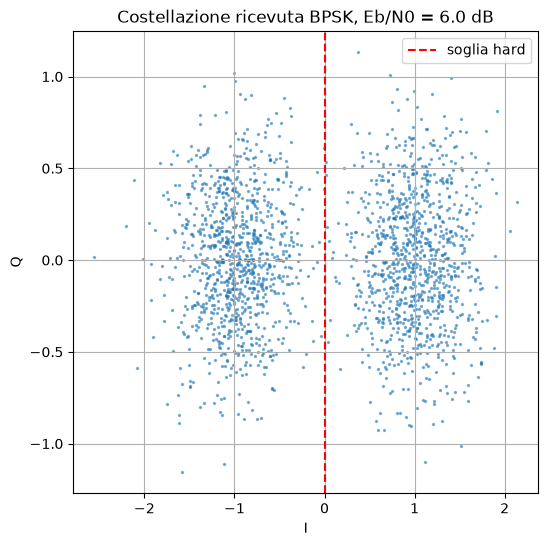

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# Parametri
N_bits = 10000
EbN0_dB = 6.0
EbN0 = 10**(EbN0_dB / 10)

# Bit trasmessi
bits = rng.integers(0, 2, N_bits)
# Simboli BPSK: 0 -> -1, 1 -> +1
symbols = 2 * bits - 1
# Energia per simbolo (normalizzata a 1)
Es = 1.0
# Varianza del rumore per componente (complessa): N0/2
N0 = Es / EbN0
sigma2 = N0 / 2

# Canale AWGN (complesso)
noise = rng.normal(0, np.sqrt(sigma2), N_bits) + 1j * rng.normal(0, np.sqrt(sigma2), N_bits)
r = symbols + noise

# Demodulazione hard: segno della parte reale
bits_hat_hard = (r.real > 0).astype(int)

# Demodulazione soft: LLR = 4*sqrt(Es)/N0 * Re(r)
LLR = 4 * np.sqrt(Es) / N0 * r.real
bits_hat_soft = (LLR > 0).astype(int)

# Tasso di errore
ber_hard = np.mean(bits_hat_hard != bits)
ber_soft = np.mean(bits_hat_soft != bits)
print(f"BER hard = {ber_hard:.5f}, BER soft = {ber_soft:.5f}")

# Costellazione ricevuta
plt.figure(figsize=(6, 6))
plt.scatter(r.real[:2000], r.imag[:2000], s=2, alpha=0.5)
plt.axvline(0, color='r', linestyle='--', label='soglia hard')
plt.xlabel('I')
plt.ylabel('Q')
plt.title(f'Costellazione ricevuta BPSK, Eb/N0 = {EbN0_dB} dB')
plt.legend()
plt.grid(True)
plt.show()

Interpretazione. La costellazione ricevuta è una nuvola di punti intorno a $\pm1$ sull'asse II, con dispersione dovuta al rumore. La soglia a $0$ separa le due decisioni. La soft decision (LLR) produce lo stesso segno della hard decision, ma con un valore assoluto che misura l'affidabilità: i punti vicini alla soglia hanno LLR piccolo (bassa affidabilità), quelli lontani hanno LLR grande (alta affidabilità). È questa informazione che il decodificatore di canale userà per correggere gli errori.

## 8.3 Sincronizzazione

### Osservazione 8.3.1 — Perché la sincronizzazione è il problema più difficile

La demodulazione ottima (ML) presuppone che il ricevitore conosca tre cose: la fase della portante, l'istante di campionamento ottimo, e l'allineamento dei frame. Nella realtà, nessuna delle tre è nota a priori: il trasmettitore e il ricevitore hanno oscillatori diversi, il canale introduce ritardi variabili, e i frame non hanno un allineamento prestabilito. La sincronizzazione è l'insieme delle tecniche con cui il ricevitore stima questi parametri dai dati ricevuti.

La sincronizzazione è il problema più difficile della catena di ricezione, per tre ragioni:

1. **È un problema di stima:** in condizioni di basso SNR: il ricevitore deve stimare parametri continui (fase, frequenza, timing) da osservazioni rumorose.

2. **È un problema di decisione:** la stima può essere sbagliata, e un errore di sincronizzazione produce una raffica di errori (burst) molto peggiore di un errore isolato.

3. **È un problema di stato:** il ricevitore deve mantenere il "lock" nel tempo, e rilevare quando lo perde. È un sistema dinamico, non una stima una tantum.

### Definizione 8.3.2 — Sincronizzazione di portante

La sincronizzazione di portante stima e compensa l'offset di frequenza $\delta f$ e l'offset di fase $\delta \phi$ tra l'oscillatore del trasmettitore e quello del ricevitore. Il segnale in banda base, prima della compensazione, è:

$$
r[n] = a[n] e^{j(2\pi\delta f n T_s + \delta \phi)} + w[n]
$$

L'offset di frequenza produce una rotazione della costellazione nel tempo: se non compensato, i simboli ruotano di $2\pi \delta f T_s$ a ogni campione, e dopo un certo numero di simboli la costellazione è completamente ruotata. L'offset di fase produce una rotazione costante, che sposta tutti i punti della stessa quantità.

Le tecniche principali sono:

Costas loop: un anello ad aggancio di fase (PLL) che stima la fase e la frequenza, e compensa la rotazione. È la tecnica più usata per PSK e QAM. La sua implementazione è un filtro passa-basso che insegue l'errore di fase, con una larghezza di banda che controlla il compromesso tra velocità di aggancio e rumore residuo.

Stima data-aided: si usano simboli pilota (noti al ricevitore) per stimare la fase. È precisa ma consuma banda (i piloti non trasportano informazione).

Stima blind: si stima la fase dai simboli stessi, sfruttando la struttura della costellazione (es. per QPSK, la fase è stimata dalla quarta potenza del segnale, che elimina la modulazione). È efficiente in banda ma meno precisa.

### Osservazione 8.3.3 — La sincronizzazione di portante è un problema di stima ricorsiva.

Il Costas loop è un filtro ricorsivo che stima la fase a ogni campione, aggiornando la stima in base all'errore. La sua dinamica è descritta da un'equazione differenziale (o alle differenze), e la sua stabilità dipende dai parametri del loop (guadagno, larghezza di banda). Un loop troppo stretto converge lentamente ma è robusto al rumore; un loop troppo largo converge in fretta ma è rumoroso. È lo stesso trade-off bias-varianza che si incontra in ogni stimatore ricorsivo.

### Definizione 8.3.4 — Sincronizzazione di timing

La sincronizzazione di timing stima l'istante ottimo di campionamento del simbolo. Il segnale in banda base è una sequenza di impulsi $g(t)$ centrati su istanti $nT + \tau$, dove $\tau$ è il ritardo (sconosciuto) tra trasmettitore e ricevitore. Il ricevitore deve stimare $\tau$ e campionare nel punto di massimo (o nel punto ottimo secondo un criterio).

Le tecniche principali sono:

**Early-late gate**: si campiona il segnale in due istanti, uno in anticipo e uno in ritardo rispetto all'istante nominale, e si confrontano le due energie. Se l'energia è maggiore in anticipo, il timing è in ritardo; se è maggiore in ritardo, il timing è in anticipo. L'errore corregge la stima.

**Mueller-Müller**: si usa la differenza tra campioni consecutivi per stimare l'errore di timing, senza bisogno di due campionamenti per simbolo. È efficiente ma richiede una buona stima iniziale.

**Gardner**: simile a Mueller-Müller ma robusto a offset di frequenza. È usato in molti demodulatori.

**Campionamento frazionario**: si campiona a una frequenza multipla di quella di simbolo (es. $4\times$), e si interpola per ottenere il valore all'istante ottimo. È la tecnica usata nei ricevitori software-defined, dove il campionamento è a frequenza fissa e l'interpolazione è digitale.

### Osservazione 8.3.5 — La sincronizzazione di timing è critica per l'ISI.

Un errore di timing produce interferenza intersimbolica (ISI): il campione include non solo il simbolo corrente, ma anche una parte dei simboli adiacenti. L'ISI degrada la costellazione (i punti si allargano) e aumenta la probabilità di errore. Per questo la sincronizzazione di timing deve essere precisa (entro una frazione di $T$), e il filtro di ricezione (matched filter o root-raised-cosine) deve essere progettato per minimizzare l'ISI all'istante di campionamento.

### Definizione 8.3.6 — Sincronizzazione di frame

La sincronizzazione di frame individua l'inizio dei frame nel flusso di simboli (o di bit). Si basa su un marcatore di sincronizzazione (sync word, sync marker, preamble) noto al ricevitore: una sequenza di bit (o di simboli) che compare all'inizio di ogni frame. Il ricevitore scorre il flusso e cerca il marcatore, usando una correlazione o un automa a stati.

Formalmente, se il marcatore è una sequenza $m = (m_1, \dots, m_L)$ di $L$ bit, il ricevitore calcola la correlazione tra la finestra corrente di $L$ bit e $m$:

$$
C[n] = \sum_{k = 0}^{L - 1} r[n + k]\cdot m_k
$$

e dichiara "frame trovato" quando $C[n]$ supera una soglia. La soglia è scelta per bilanciare probabilità di detection (trovare il frame quando c'è) e probabilità di falsa sincronizzazione (trovare un frame quando non c'è).

### Definizione 8.3.7 — Probabilità di falsa sincronizzazione

La probabilità di falsa sincronizzazione è la probabilità che il ricevitore dichiari "frame trovato" in una posizione in cui non c'è un frame, a causa del rumore o di una coincidenza casuale. Per un marcatore di $L$ bit e un flusso di bit casuali (o rumorosi), la probabilità che una finestra di $L$ bit coincida con il marcatore è: 

$$
P_{fs} = 2^{-L}
$$

per un canale senza errori. Su un flusso di $N$ bit, la probabilità di almeno una falsa sincronizzazione è:

$$
P_{fs}^{(N)} = 1 - (1 - 2^{-L})^{N} \approx N \cdot 2^{-L}
$$

per $N >> 2^{L}$. Per esempio, con $L = 16$ e $N = 10^6$ bit, $P^{(N)}_{fs} \approx 10^6$.
$2^{-16} \approx 15$, cioè ci si aspettano circa $15$ falsi allineamenti. con $L = 32$, $P_{fs}^{(N)}\approx 10^6 \cdot 2^{-32} \approx 2.3 \times 10^{-4}$, trascurabile.

In presenza di errori (BER $p$), la probabilità che una finestra di $L$ bit coincida con il marcatore è:

$$
P_{fs} = (1-p)^L \quad \text{(se il marcatore è tutto uguale)}
$$

o, più in generale, la probabilità che la correlazione superi la soglia. In pratica, si sceglie $L$ in modo che $P_{fs}$ sia inferiore a una specifica (es. $10^{-6}$ per frame), e si usa una soglia di correlazione (invece della coincidenza esatta) per tollerare alcuni errori nel marcatore. 

### Osservazione 8.3.8 — Il marcatore di sincronizzazione è un compromesso tra overhead e robustezza.

Un marcatore più lungo riduce $P_{fs}$ ma aumenta l'overhead (bit sprecati). Un marcatore più corto riduce l'overhead ma aumenta $P_{fs}$. La scelta dipende dalla statistica del link: per un link con BER bassa, $L = 16$ è sufficiente; per un link con BER alta o con molti frame, $L = 32$ è più sicuro. In CCSDS, il marcatore (ASM) è di $32$ bit, scelto per rendere $P_{fs}$ trascurabile anche su missioni lunghe.

### Osservazione 8.3.9 — Il lock e la perdita di lock

La sincronizzazione non è un evento una tantum: è uno stato che il ricevitore mantiene nel tempo. Si parla di lock quando il ricevitore è allineato (portante, timing, frame), e di perdita di lock (loss of lock) quando l'allineamento è perso a causa di rumore, fading, o errori. Il comportamento del ricevitore è descritto da un modello a stati (es. Markov): stato "locked" e stato "unlocked", con probabilità di transizione che dipendono dall'SNR e dalla qualità della stima.

Un ricevitore ben progettato ha un meccanismo di rilevamento della perdita di lock: se la correlazione del marcatore scende sotto una soglia per un certo numero di frame consecutivi, il ricevitore dichiara "unlocked" e riavvia la procedura di sincronizzazione. Questo evita che un errore temporaneo produca una raffica di frame corrotti.

## 8.4 Framing 

### Definizione 8.4.1 — Che cos'è il framing

Il framing è l'operazione che segmenta il flusso di bit (o di simboli) in unità discrete (frame), ciascuna con un inizio, una fine, e una struttura interna. È il livello che trasforma un flusso continuo in una sequenza di oggetti, e che permette al ricevitore di:

1. **Riconoscere** l'inizio e la fine di ogni frame.
2. **Verificare** l'integrità del frame (tramite CRC o FCS).
3. **Estrarre** l'identità del frame (header).
4. **Ancorare** il frame a un istante temporale (timestamp).

Senza framing, il flusso di bit è ininterpretabile: non c'è modo di sapere dove finisce un frame e dove inizia il successivo, né di verificare se il frame è corrotto.

### Definizione 8.4.2 — Tecniche di framing

Le tecniche di framing si classificano in base a come il ricevitore determina l'inizio e la fine del frame:

1. Framing a lunghezza fissa con marcatore di sincronizzazione. Il frame ha una lunghezza fissa $L_f$, e inizia con un marcatore $L_m$ di bit. Il ricevitore cerca il marcatore, e da lì legge esattamente $L_f$ bit. Esempio: CCSDS TM (frame di $1115$ byte, marcatore ASM di $32$ bit).

2. Framing a delimitatori (flag). Il frame è delimitato da un pattern di bit (flag) all'inizio e alla fine. Il ricevitore cerca il flag di fine, e il frame è ciò che sta tra due flag. Esempio: $AX.25$ (flag $0x7E$), HDLC.

3. Framing a conteggio di lunghezza. Il frame inizia con un campo di lunghezza, che dice quanti byte seguono. Il ricevitore legge la lunghezza, e legge esattamente quel numero di byte. Esempio: molti protocolli custom, Ethernet (campo length/type).

4. Framing a stuffing. Il frame è delimitato da un flag, ma il flag può comparire nel payload; per evitare ambiguità, il trasmettitore "stuffa" (inserisce) bit o byte aggiuntivi quando il flag compare nel payload, e il ricevitore li rimuove. Esempio: COBS, bit stuffing in HDLC.

### Osservazione 8.4.3 — La scelta della tecnica di framing determina la complessità del ricevitore e l'overhead.

Il framing a lunghezza fissa è il più semplice (il ricevitore sa sempre quanti bit leggere), ma spreca banda quando i frame sono piccoli (padding). Il framing a delimitatori è più efficiente in banda, ma richiede stuffing (overhead) e un parser più complesso. Il framing a conteggio è flessibile, ma richiede che il campo di lunghezza sia protetto (altrimenti un errore nel campo produce una lettura sbagliata). La scelta dipende dal compromesso tra semplicità, efficienza e robustezza.

### Definizione 8.4.4 — Byte stuffing e COBS

Il byte stuffing è una tecnica per evitare che il delimitatore di frame compaia nel payload. Se il delimitatore è il byte $0x7E$, il trasmettitore sostituisce ogni $0x7E$ nel payload con una sequenza di escape (es. $0x7D \; 0x5E$), e il ricevitore inverte la sostituzione. Lo svantaggio è che l'overhead è variabile (dipende dal contenuto del payload), e la sostituzione richiede una scansione byte per byte.

COBS (Consistent Overhead Byte Stuffing) è una tecnica più efficiente: rimuove tutti gli zeri dal payload, e li sostituisce con un byte di conteggio che indica la distanza dal prossimo zero. Il risultato è che il byte $0x00$ può comparire solo come delimitatore di frame, mai come dato. L'overhead è limitato (al massimo $1$ byte ogni $254$ byte di payload), e la codifica/decodifica è semplice e veloce.

Formalmente, COBS codifica un blocco di $n$ byte in $n + [n/254]$ byte (al massimo). 

### Definizione 8.4.5 — Frame a lunghezza fissa vs variabile

Frame a lunghezza fissa: tutti i frame hanno la stessa lunghezza $L_f$. Vantaggi: semplicità del ricevitore, sincronizzazione banale (trovato il marcatore, si legge $L_f$ bit). Svantaggi: spreco di banda se i payload sono più piccoli di $L_f$ (padding), e impossibilità di adattarsi a payload di dimensioni diverse.

Frame a lunghezza variabile: ogni frame ha una lunghezza diversa, specificata da un campo di lunghezza o da un delimitatore. Vantaggi: efficienza in banda, adattabilità. Svantaggi: parser più complesso, necessità di proteggere il campo di lunghezza (un errore produce una lettura sbagliata), e rischio di frame "lunghi" che occupano il canale.

La scelta dipende dall'applicazione: per telemetria a pacchetti di dimensione fissa (es. campioni di sensori), il frame a lunghezza fissa è appropriato; per telemetria a pacchetti di dimensione variabile (es. eventi, comandi), il frame a lunghezza variabile è necessario.

## 8.5 Il frame come unità di dato

### Definizione 8.5.1 — Struttura del frame

Indipendentemente dalla tecnica di framing, un frame contiene sempre le stesse componenti funzionali

1. **Marcatore di sincronizzazione** (o delimitatore): permette al ricevitore di allinearsi.

2. **Header**: metadati che identificano il frame (ID, tipo, contatore di sequenza, lunghezza).

3. **Payload**: i dati veri e propri

4. **Codice di rilevamento/correzione errori** (CRC, FCS, FEC): permette di verificare l'integrità.

5. **Timestamp** (esplicito o implicito): ancora il frame a un istante.

### Definizione 8.5.2 — Integrità: CRC e FCS

Il CRC (Cyclic Redundancy Check) è un codice di rilevamento errori basato sulla divisione polinomiale in GF(2). Il trasmettitore calcola il resto della divisione del messaggio per un polinomio generatore $G(x)$ di grado $r$, e appende il resto ($r$ bit) al messaggio. Il ricevitore esegue la stessa divisione e verifica che il resto sia zero.

Le proprietà del CRC
- Rileva tutti gli errori singoli;
- Rileva tutti gli errori doppi (se $G(x)$ ha un fattore $(x+1)$);
- Rileva tutti i burst di errore di lunghezza $\leq r$;
- Probabilità di errore non rilevato $\approx 2^{-r}$ per errori casuali;

Il FCS (Frame Check Sequence) è il campo che contiene il CRC. In CCSDS il FCS è un CRC-$16$; in Ethernet, è un CRC-32. In AX.$25$, il FCS è un CRC-16 (polinomio $0x1021$).

La probabilità di frame corrotto (PER, Packet Error Rate) è la probabilità che un frame contenga almeno un errore non corretto. Per errori indipendenti con BER $p$ e frame di $n$ bit: 

$$
\operatorname{PER} = 1 - (1 - p)^n
$$

Per $p$ piccola, $\operatorname{PER} \approx np$. Per esempio, con $p = 10^{-5}$ e $n = 1000$, $\operatorname{PER} \approx 10^{-2}$, cioè l'$1\%$ dei frame è corrotto. Questo mostra che la PER è $n$ volte la BER: un frame lungo è più esposto di un frame corto. 

### Osservazione 8.5.3 — La PER è la metrica operativa, la BER è la metrica di link.

In un MCC, ciò che conta è la PER, perché il frame è l'unità di dato. Una BER di $10^{-5}$ può sembrare bassa, ma con frame di $1000$ bit produce una PER dell'$1\%$, che su $1000$ frame significa $10$ frame persi. La PER dipende dalla lunghezza del frame, oltre che dalla BER: frame più corti hanno PER più bassa a parità di BER. Questo è il motivo per cui, in ambienti rumorosi, si usano frame corti (a costo di più overhead).

### Definizione 8.5.4 — Identità: header e indirizzamento

L'header contiene i metadati che identificano il frame. I campi tipici sono:

- **ID del veicolo**: identifica il satellite o il lanciatore (in CCSDS, $10$ bit);
- **Tipo di frame**: distingue telemetria, comando, housekeeping, ecc;
- **Canale virtuale**: identifica uno dei canali multiplexati sullo stesso link (in CCSDS, $3$ bit);
- **Contatore di sequenza**: permette di rilevare le perdite (in CCSDS, $8$ bit per il master channel, $8$ bit per il virtual channel);
- **Lunghezza**: per frame a lunghezza variabile;
- **Flag di stato**: indicano la presenza di secondary header, la frammentazione, l'ordine dei pacchetti.

L'header è critico per l'interpretazione del frame: senza di esso, il payload è opaco. Un errore nell'header può rendere il frame ininterpretabile, anche se il payload è corretto. Per questo, in molti protocolli, l'header è protetto da un CRC separato (header CRC) oltre al CRC del frame intero.

### Definizione 8.5.5 — Timestamp: esplicito e implicito

Il timestamp ancora il frame a un istante temporale. Può essere:

- **Esplicito**: inserito a bordo, con un orologio di bordo. La sua precisione dipende dalla sincronizzazione dell'orologio (GPS, PPS). È il caso di CCSDS, dove il time code è nel secondary header.
- **Implicito**: il tempo di arrivo misurato dal ricevitore. È meno preciso (include la latenza del link e del processing), ma è l'unica opzione quando il veicolo non ha un orologio sincronizzato.

L'incertezza del timestamp si propaga all'analisi: se il timestamp ha un jitter di $10$ ms, la stima della derivata di un parametro avrà un'incertezza che dipende da quel jitter. In un MCC, il timestamp non è un dettaglio implementativo: è una fonte di incertezza che va documentata e, se possibile, quantificata.

### Definizione 8.5.6 — Contatori di sequenza e rilevamento perdite

Il contatore di sequenza è un campo dell'header che incrementa di 1 a ogni frame (o a ogni pacchetto). Il ricevitore confronta il contatore del frame corrente con quello del frame precedente: se c'è un salto, sa che uno o più frame sono andati persi, e può stimare quanti.

In CCSDS, ci sono due contatori: il Master Channel Frame Count ($8$ bit, incrementa a ogni frame) e il Virtual Channel Frame Count ($8$ bit, incrementa a ogni frame del canale virtuale). Il primo rileva le perdite sul canale fisico, il secondo su ciascun canale virtuale.

In AX.$25$, il contatore è il campo N(S) nei frame I (information), ma non c'è contatore nei frame UI (unnumbered information), che sono quelli usati per la telemetria broadcast. Questo significa che, in AX.$25$, le perdite di frame UI non sono rilevabili a livello di data link: è il livello applicativo che deve gestirle (es. con un contatore nel payload).

### Osservazione 8.5.7 — Il contatore di sequenza è lo strumento più semplice per la gestione delle perdite.

Senza contatore, il ricevitore non sa se un frame è perso o se non è mai stato trasmesso. Con il contatore, sa esattamente quanti frame mancano, e può decidere come gestirli (ignorare, interpolare, richiedere ritrasmissione). La scelta della modalità (modulo $256$, modulo $1024$, ecc.) dipende dalla massima perdita che si vuole rilevare: un contatore a $8$ bit rileva perdite fino a $255$ frame, un contatore a $16$ bit fino a $65535$

## 8.6 Analisi statistica del framing

### Definizione 8.6.1 — Probabilità di falsa sincronizzazione (rivisitata)

La probabilità di falsa sincronizzazione dipende dalla lunghezza del marcatore $L$, dalla BER $p$, e dalla soglia di correlazione. Per un marcatore a coincidenza esatta, la probabilità che una finestra casuale di $L$ bit coincida con il marcatore è:

$$
P_{fs} = (1-p)^L
$$

per un canale con BER $p$ (se il marcatore è tutto uguale) o, più in generale, la probabilità che la correlazione superi la soglia. Su un fisso di $N$ bit, la probabilità di almeno una falsa sincronizzazione è: 

$$
P_{fs}^{(N)} = 1 - (1 - P_{fs})^N \approx N \cdot P_{fs}
$$

per $NP_{fs}$ piccolo.

### Definizione 8.6.2 — Probabilità di frame corrotto

La probabilità che un frame di nn bit contenga almeno un errore non corretto è: 

$$
P_{\text{corrotto}} = 1 - (1 - p)^n \approx np
$$

per $p$ piccola. Se il CRC ha $r$ bit, la probabilità che un frame corrotto passi il CRC (falso negativo) è:

$$
P_{\text{miss}} = P_{\text{corrotto}} \cdot 2^{-r}
$$

per errori casuali. Per esempio, con $n = 1000$, $p = 10^{-5}$, $r = 16$: $P_{\text{corrotto}} \approx 10^{-2}$, $P_{\text{miss}} \approx 10^{-2} \cdot 2^{-16} \approx 1.5 \times 10^{-7}$. Questo mostra che il CRC-16 è sufficiente per la maggior parte delle applicazioni: la probabilità di un frame corrotto non rilevato è molto bassa.

### Definizione 8.6.3 — Probabilità di frame perso

La probabilità che un frame venga perso (non ricevuto affatto) dipende dal meccanismo di perdita:

- **Perdita per mancata sincronizzazione:** il marcatore non viene trovato, e il frame è perso. Probabilità $P^{sync}_{miss}$ 

- **Perdita per CRC fallito:** il frame è ricevuto ma corrotto, e viene scartato. Probabilità $P_{\text{corrotto}}$

- **Perdita per outage** il link è interrotto (finestra chiusa, puntamento perso). Probabilità $P_{\text{outage}}$, che dipende dalla missione

La probabilità totale di perdita è:

$$
P_{\text{perso}} = 1 - (1 - P^{\text{sync}}_{\text{miss}}) (1 - P_{\text{corrotto}})(1 - P_{\text{outage}})
$$


Per $P$ piccole, $P_{\text{perso}} \approx P^{\text{sync}}_{\text{miss}} + P_{\text{corretto}} + P_{\text{outage}}$

### Definizione 8.6.4 — Modello di Markov per lo stato di sincronizzazione

Il ricevitore può essere modellato come un processo di Markov a due stati: LOCK (sincronizzato) e UNLOCK (non sincronizzato). Le transizioni sono:

- Da LOCK a UNLOCK: probabilità $P_{lu}$ (perdita di lock), che dipende dall'SNR e dalla qualità della stima;

- Da UNLOCK a LOCK: probabilità $P_{ul}$ (acquisizione di lock), che dipende dalla procedura di sincronizzazione e dal tempo di acquisizione.

La distribuzione stazionaria dello stato è: 

$$
\pi_{\text{LOCK}} = \frac{P_{ul}}{P_{lu} + P_{ul}}, \quad \pi_{\text{UNLOCK}} = \frac{P_{lu}}{P_{lu} + P_{ul}}
$$

e la probabilità di essere in LOCK in un dato istante è $\pi_{\text{LOCK}}$. Il tempo medio tra due perdite di lock (mean time to lose lock, MTTL) è $1/P_{lu}$, e il tempo medio di acquisizione è $1/P_{ul}$. Un ricevitore ben progettato ha $\pi_{\text{lock}}$ vicino a $1$, e MTTL molto maggiore del tempo di acquisizione.

### Osservazione 8.6.5 — Il modello di Markov è lo strumento per progettare la sincronizzazione.

La scelta dei parametri del loop (larghezza di banda, guadagno) determina $P_{lu}$ e $P_{ul}$, e quindi $\pi_{\text{LOCK}}$. Un loop troppo stretto ha $P_{\text{lu}}$ bassa (buona stabilità) ma $P_{\text{ul}}$ bassa (lenta acquisizione); un loop troppo largo ha $P_{\text{lu}}$ alta (instabilità) ma $P_{\text{ul}}$ alta (acquisizione veloce). Il progetto ottimo dipende dalla statistica del canale e dai requisiti della missione: per un link stabile, si privilegia la stabilità; per un link con fading, si privilegia la reattività.

### Esempio 8.7.1 — Rilevamento di un marcatore di sincronizzazione

In [2]:
import numpy as np

rng = np.random.default_rng(42)

# Marcatore di 16 bit (scelto casualmente)
marker = np.array([1,0,1,1,0,0,1,0,1,1,1,0,0,1,0,1])
L = len(marker)

# Flusso di bit con un frame inserito a caso
N = 10000
stream = rng.integers(0, 2, N)
start = 3456
stream[start:start+L] = marker

# Aggiungi errori (BER = 1e-3)
p = 1e-3
errors = rng.random(N) < p
stream_err = np.bitwise_xor(stream, errors.astype(int))

# Correlazione scorrevole (conteggio delle coincidenze)
def correlate(stream, marker):
    L = len(marker)
    scores = np.zeros(len(stream) - L + 1, dtype=int)
    for i in range(len(scores)):
        scores[i] = np.sum(stream[i:i+L] == marker)
    return scores

scores = correlate(stream_err, marker)
# Soglia: almeno L-2 coincidenze (tollera 2 errori)
threshold = L - 2
detections = np.where(scores >= threshold)[0]
print(f"Marcatore vero a {start}, rilevato a {detections}")

# Probabilità di falsa sincronizzazione (teorica)
P_fs = 2**-L
P_fs_N = 1 - (1 - P_fs)**N
print(f"P_fs (per posizione) = {P_fs:.2e}")
print(f"P_fs su {N} bit = {P_fs_N:.2e}")

Marcatore vero a 3456, rilevato a [ 142  233 1948 2077 2386 2448 2652 3176 3456 3712 3809 3911 3930 4575
 5462 6314 6321 6717 7123 7576 7888 8401 8537 8777 9639]
P_fs (per posizione) = 1.53e-05
P_fs su 10000 bit = 1.42e-01


**Interpretazione**. Il codice inserisce un marcatore in un flusso di bit, aggiunge errori, e cerca il marcatore con una correlazione che tollera 2 errori. La soglia $L−2$ riduce la probabilità di falsa sincronizzazione (rispetto alla coincidenza esatta) ma aumenta la probabilità di detection in presenza di errori. La probabilità teorica di falsa sincronizzazione ($2^{-16} \approx 1.5 \times 10^{-5}$) è confermata dall'assenza di falsi positivi nel flusso (a parte il marcatore vero).

### Esempio 8.7.2 — Calcolo della PER in funzione della BER e della lunghezza del frame

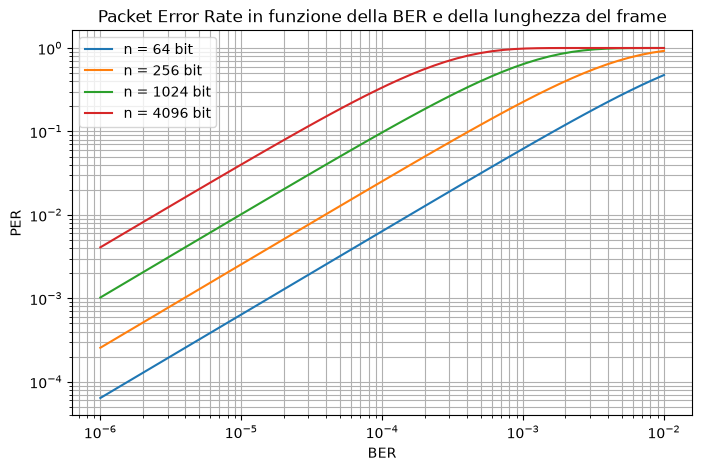

In [3]:
import numpy as np
import matplotlib.pyplot as plt

BER = np.logspace(-6, -2, 50)
frame_lengths = [64, 256, 1024, 4096]

plt.figure(figsize=(8, 5))
for n in frame_lengths:
    PER = 1 - (1 - BER)**n
    plt.loglog(BER, PER, label=f"n = {n} bit")

plt.xlabel("BER")
plt.ylabel("PER")
plt.title("Packet Error Rate in funzione della BER e della lunghezza del frame")
plt.grid(True, which="both")
plt.legend()
plt.show()

**Interpretazione**. Il grafico mostra che, a parità di BER, frame più lunghi hanno PER più alta. Per una BER di $10^{-4}$, un frame di $64$ bit ha PER $\approx 0.6\%$, un frame di $4096$ bit ha PER $\approx 34\%$. Questo è il motivo per cui, in ambienti rumorosi, si usano frame corti, e perché la scelta della lunghezza del frame è un parametro di progetto che dipende dalla statistica del link
